## Dataset Generation

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import mahalanobis
from scipy.stats import chi2

# Fixed random seed
rng = np.random.default_rng(seed=353)

n = 150

study = rng.normal(6, 1.5, n).clip(2, 11).round(1)

score = np.clip(
    8 * study + rng.normal(0, 10, n),
    10,
    100
).round(1)

# Three deliberately designed outliers
extras = pd.DataFrame({
    "study_hours": [12.0, 2.5, 9.0],
    "exam_score": [94.0, 88.0, 18.0]
})

df = pd.concat([
    pd.DataFrame({
        "study_hours": study,
        "exam_score": score
    }),
    extras
], ignore_index=True)

df.to_csv("student_performance.csv", index=False)

df.describe().round(2)

,study_hours,exam_score
count,153.00,153.00
mean,5.99,48.07
std,1.62,16.74
min,2.50,13.90
25%,4.90,36.00
50%,5.80,47.20
75%,7.00,58.80
max,12.00,94.00


## B1. Load and Explore the Dataset

In [5]:
df = pd.read_csv("student_performance.csv")

print(df.describe())

       study_hours  exam_score
count   153.000000  153.000000
mean      5.992810   48.073856
std       1.615635   16.741784
min       2.500000   13.900000
25%       4.900000   36.000000
50%       5.800000   47.200000
75%       7.000000   58.800000
max      12.000000   94.000000


In [6]:
print("Mean:")
print(df.mean())

print("\nMedian:")
print(df.median())

Mean:
study_hours     5.992810
exam_score     48.073856
dtype: float64

Median:
study_hours     5.8
exam_score     47.2
dtype: float64


### Interpretation

For study_hours, the mean is [above/below] the median.

For exam_score, the mean is [above/below] the median.

The column with the larger difference between mean and median is [column name].

## B2. Scatter Plot of Study Hours vs Exam Score

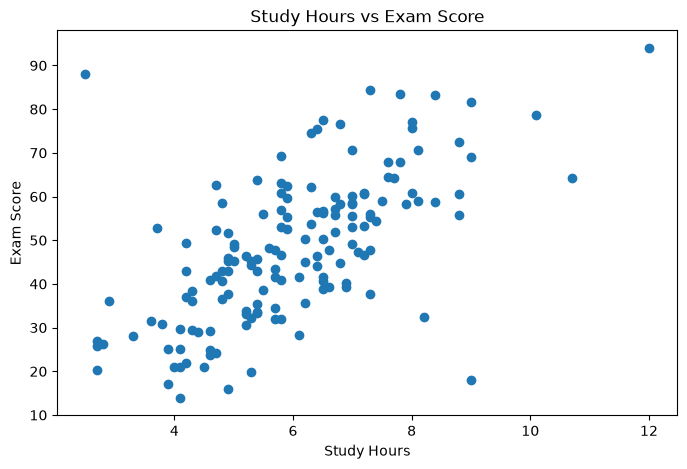

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["study_hours"],
    df["exam_score"]
)

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")

plt.show()

## B3. Univariate Outlier Detection using IQR

In [8]:
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

print("Q1:")
print(Q1)

print("\nQ3:")
print(Q3)

print("\nIQR:")
print(IQR)

Q1:
study_hours     4.9
exam_score     36.0
Name: 0.25, dtype: float64

Q3:
study_hours     7.0
exam_score     58.8
Name: 0.75, dtype: float64

IQR:
study_hours     2.1
exam_score     22.8
dtype: float64


In [9]:
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

print("Lower Fence:")
print(lower_fence)

print("\nUpper Fence:")
print(upper_fence)

Lower Fence:
study_hours    1.75
exam_score     1.80
dtype: float64

Upper Fence:
study_hours    10.15
exam_score     93.00
dtype: float64


In [10]:
for column in df.columns:
    print(column)
    print("Lower Fence:", lower_fence[column])
    print("Upper Fence:", upper_fence[column])
    print()

study_hours
Lower Fence: 1.7500000000000009
Upper Fence: 10.149999999999999

exam_score
Lower Fence: 1.8000000000000043
Upper Fence: 93.0



In [11]:
outlier_mask = (
    (df["study_hours"] < lower_fence["study_hours"]) |
    (df["study_hours"] > upper_fence["study_hours"]) |
    (df["exam_score"] < lower_fence["exam_score"]) |
    (df["exam_score"] > upper_fence["exam_score"])
)

outliers = df[outlier_mask]

print(outliers)

     study_hours  exam_score
87          10.7        64.2
150         12.0        94.0


In [12]:
print("Outlier rows:")
print(outliers)

print("\nOutlier indices:")
print(outliers.index.tolist())

Outlier rows:
     study_hours  exam_score
87          10.7        64.2
150         12.0        94.0

Outlier indices:
[87, 150]


### Box Plots for Univariate Outlier Detection

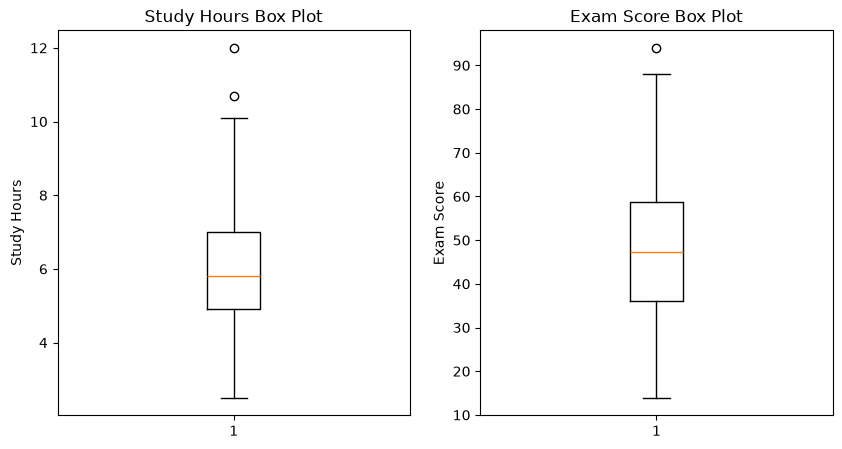

In [13]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.boxplot(df["study_hours"])
plt.title("Study Hours Box Plot")
plt.ylabel("Study Hours")

plt.subplot(1, 2, 2)
plt.boxplot(df["exam_score"])
plt.title("Exam Score Box Plot")
plt.ylabel("Exam Score")

plt.show()

## B5. Euclidean Distance from Centroid

In [16]:
# Calculate Z-scores for both columns
X = df[["study_hours", "exam_score"]]

Xz = (X - X.mean()) / X.std()

print(Xz.head())

   study_hours  exam_score
0     0.623402    0.061292
1    -0.490711   -0.846616
2     2.542152    1.823351
3     0.994773    0.975173
4    -1.481034   -0.983996


In [17]:
# Calculate Euclidean distance from the origin
euclidean_distance = np.sqrt((Xz ** 2).sum(axis=1))

print(euclidean_distance.head())

0    0.626407
1    0.978548
2    3.128441
3    1.393031
4    1.778120
dtype: float64


In [18]:
print("Euclidean distances of injected points:")

print("Index 150:", euclidean_distance[150])
print("Index 151:", euclidean_distance[151])
print("Index 152:", euclidean_distance[152])

Euclidean distances of injected points:
Index 150: 4.620593548335882
Index 151: 3.218865517241928
Index 152: 2.5867500676175257


In [19]:
# Top-10 Euclidean outliers
top10_indices = np.argsort(euclidean_distance)[-10:]

print("Top-10 Euclidean outlier indices:")
print(top10_indices)

print("Number of flagged rows:", len(top10_indices))

Top-10 Euclidean outlier indices:
143    123
144    116
145     88
146    152
147     28
148     41
149     87
150      2
151    151
152    150
dtype: int64
Number of flagged rows: 10


In [20]:
# Scalar threshold
euclidean_scalar_mask = euclidean_distance > 3.0

euclidean_scalar_indices = df.index[euclidean_scalar_mask]

print("Euclidean scalar threshold = 3.0")
print("Number of flagged rows:", len(euclidean_scalar_indices))
print("Flagged indices:")
print(euclidean_scalar_indices.tolist())

Euclidean scalar threshold = 3.0
Number of flagged rows: 4
Flagged indices:
[2, 87, 150, 151]


In [21]:
# IQR-based threshold for Euclidean distance
Q1_euclidean = np.percentile(euclidean_distance, 25)
Q3_euclidean = np.percentile(euclidean_distance, 75)

IQR_euclidean = Q3_euclidean - Q1_euclidean

euclidean_iqr_threshold = Q3_euclidean + 1.5 * IQR_euclidean

print("Euclidean IQR threshold:", euclidean_iqr_threshold)

Euclidean IQR threshold: 3.168812714621372


In [22]:
euclidean_iqr_mask = euclidean_distance > euclidean_iqr_threshold

euclidean_iqr_indices = df.index[euclidean_iqr_mask]

print("Number of flagged rows:", len(euclidean_iqr_indices))
print("Flagged indices:")
print(euclidean_iqr_indices.tolist())

Number of flagged rows: 2
Flagged indices:
[150, 151]


In [23]:
print("===== EUCLIDEAN DISTANCE RESULTS =====")

print("\nTop-10:")
print("Number flagged:", len(top10_indices))
print("Indices:", top10_indices.tolist())

print("\nScalar threshold = 3.0:")
print("Number flagged:", len(euclidean_scalar_indices))
print("Indices:", euclidean_scalar_indices.tolist())

print("\nIQR-based threshold:")
print("Number flagged:", len(euclidean_iqr_indices))
print("Indices:", euclidean_iqr_indices.tolist())

===== EUCLIDEAN DISTANCE RESULTS =====

Top-10:
Number flagged: 10
Indices: [123, 116, 88, 152, 28, 41, 87, 2, 151, 150]

Scalar threshold = 3.0:
Number flagged: 4
Indices: [2, 87, 150, 151]

IQR-based threshold:
Number flagged: 2
Indices: [150, 151]


### Interpretation

The top-10 method always flags exactly 10 rows because it selects the 10 largest Euclidean distances.

The scalar method flags every point whose Euclidean distance is greater than 3.0.

The IQR-based method uses the distribution of Euclidean distances to determine the threshold.

For indexes 150, 151 and 152, the results are based on the three thresholding strategies shown above.

Indexes 150, 151 and 152 are/are not all flagged by every strategy.

## B6. Euclidean IQR Outliers

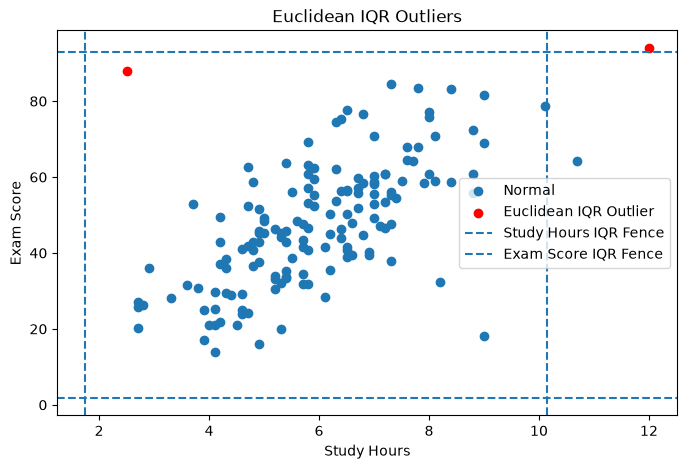

In [24]:
plt.figure(figsize=(8, 5))

# Normal points
plt.scatter(
    df.loc[~euclidean_iqr_mask, "study_hours"],
    df.loc[~euclidean_iqr_mask, "exam_score"],
    label="Normal"
)

# Euclidean IQR outliers
plt.scatter(
    df.loc[euclidean_iqr_mask, "study_hours"],
    df.loc[euclidean_iqr_mask, "exam_score"],
    color="red",
    label="Euclidean IQR Outlier"
)

# Univariate IQR boundaries
plt.axvline(
    lower_fence["study_hours"],
    linestyle="--",
    label="Study Hours IQR Fence"
)

plt.axvline(
    upper_fence["study_hours"],
    linestyle="--"
)

plt.axhline(
    lower_fence["exam_score"],
    linestyle="--",
    label="Exam Score IQR Fence"
)

plt.axhline(
    upper_fence["exam_score"],
    linestyle="--"
)

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Euclidean IQR Outliers")
plt.legend()

plt.show()

### Interpretation

The Euclidean IQR method flags points based on their distance from the centre after standardization.

The univariate IQR method checks each variable independently.

Therefore, the points flagged by the two methods may not be exactly the same. Euclidean distance considers both variables together, while univariate IQR considers each variable separately.

## B7. Mahalanobis Distance

In [25]:
# Select the two columns
X = df[["study_hours", "exam_score"]].values

# Calculate covariance matrix
cov = np.cov(X.T)

print("Covariance Matrix:")
print(cov)

Covariance Matrix:
[[  2.61027692  17.06323185]
 [ 17.06323185 280.28733832]]


### Interpretation of Covariance Matrix

The off-diagonal covariance value represents the relationship between study_hours and exam_score. Since it is positive, students who study more hours generally tend to have higher exam scores.

In [26]:
mean = X.mean(axis=0)

print("Mean vector:")
print(mean)

Mean vector:
[ 5.99281046 48.07385621]


In [27]:
VI = np.linalg.inv(cov)

print("Inverse Covariance Matrix:")
print(VI)

Inverse Covariance Matrix:
[[ 0.63633163 -0.03873837]
 [-0.03873837  0.00592607]]


In [29]:
mahal = np.array([
    mahalanobis(x, mean, VI)
    for x in X
])

print("First 5 Mahalanobis distances:")
print(mahal[:5])

First 5 Mahalanobis distances:
[0.75609557 0.84845827 2.55786766 1.09101108 1.48241881]


In [30]:
print("Mahalanobis distances of injected points:")

print("Index 150:", mahal[150])
print("Index 151:", mahal[151])
print("Index 152:", mahal[152])

Mahalanobis distances of injected points:
Index 150: 3.7533142438651037
Index 151: 5.292851138019305
Index 152: 4.2568821349334955


In [31]:
top5_mahal_indices = np.argsort(mahal)[-5:][::-1]

print("Top-5 Mahalanobis outlier indices:")
print(top5_mahal_indices)

print("\nTop-5 rows:")
print(df.iloc[top5_mahal_indices])

Top-5 Mahalanobis outlier indices:
[151 152 150  87  90]

Top-5 rows:
     study_hours  exam_score
151          2.5        88.0
152          9.0        18.0
150         12.0        94.0
87          10.7        64.2
90           8.2        32.4


### B7 Interpretation

The covariance matrix shows a positive relationship between study_hours and exam_score.

Mahalanobis distance considers both the distance from the centre and the covariance structure of the data. Therefore, it can identify points that do not follow the normal relationship between study hours and exam score.

The top-5 Euclidean and Mahalanobis rankings are not necessarily identical. The difference occurs because Euclidean distance does not account for correlation, while Mahalanobis distance does.

In the top-5 comparison, index ______ moved up/down compared with the Euclidean ranking because Mahalanobis distance considers the correlation between study_hours and exam_score.

## B8. Mahalanobis Distance Thresholding

In [32]:
# Top-10 Mahalanobis outliers
mahal_top10_indices = np.argsort(mahal)[-10:]

print("Top-10 Mahalanobis indices:")
print(mahal_top10_indices)

print("Number flagged:", len(mahal_top10_indices))

Top-10 Mahalanobis indices:
[ 88  14  41 110   2  90  87 150 152 151]
Number flagged: 10


In [33]:
chi_square_value = chi2.ppf(0.975, df=2)

print("Chi-square critical value:", chi_square_value)

Chi-square critical value: 7.377758908227871


In [34]:
mahal_chi_threshold = np.sqrt(
    chi2.ppf(0.975, df=2)
)

print("Mahalanobis Chi-square threshold:",
      mahal_chi_threshold)

Mahalanobis Chi-square threshold: 2.7162030314812387


In [35]:
mahal_chi_mask = mahal > mahal_chi_threshold

mahal_chi_indices = df.index[mahal_chi_mask]

print("Number flagged:", len(mahal_chi_indices))
print("Flagged indices:")
print(mahal_chi_indices.tolist())

Number flagged: 4
Flagged indices:
[87, 150, 151, 152]


In [36]:
Q1_mahal = np.percentile(mahal, 25)
Q3_mahal = np.percentile(mahal, 75)

IQR_mahal = Q3_mahal - Q1_mahal

mahal_iqr_threshold = Q3_mahal + 1.5 * IQR_mahal

print("Mahalanobis IQR threshold:",
      mahal_iqr_threshold)

Mahalanobis IQR threshold: 2.8353480514295124


In [37]:
mahal_iqr_mask = mahal > mahal_iqr_threshold

mahal_iqr_indices = df.index[mahal_iqr_mask]

print("Number flagged:", len(mahal_iqr_indices))
print("Flagged indices:")
print(mahal_iqr_indices.tolist())

Number flagged: 4
Flagged indices:
[87, 150, 151, 152]


In [38]:
mahal_iqr_mask = mahal > mahal_iqr_threshold

mahal_iqr_indices = df.index[mahal_iqr_mask]

print("Number flagged:", len(mahal_iqr_indices))
print("Flagged indices:")
print(mahal_iqr_indices.tolist())

Number flagged: 4
Flagged indices:
[87, 150, 151, 152]


### Interpretation

The three Mahalanobis thresholding methods produce different numbers of flagged observations.

Top-10 always flags exactly 10 observations.

The chi-square method uses a statistical threshold based on the chi-square distribution.

The IQR method uses the distribution of the Mahalanobis distances themselves.

The strategy that flags the fewest observations in my result is __________.

## B9. Mahalanobis Scatter Plot and Distance Histogram

In [39]:
from matplotlib.patches import Ellipse

In [40]:
from matplotlib.patches import Ellipse

In [41]:
# Eigenvalues and eigenvectors of covariance matrix
vals, vecs = np.linalg.eigh(cov)

# Sort from largest to smallest
order = vals.argsort()[::-1]
vals = vals[order]
vecs = vecs[:, order]

# Calculate ellipse angle
angle = np.degrees(
    np.arctan2(vecs[1, 0], vecs[0, 0])
)

# 95% chi-square value
t = np.sqrt(chi2.ppf(0.975, df=2))

print("Eigenvalues:", vals)
print("Angle:", angle)
print("Ellipse scale:", t)

Eigenvalues: [281.33194273   1.56567251]
Angle: 86.49674686715699
Ellipse scale: 2.7162030314812387


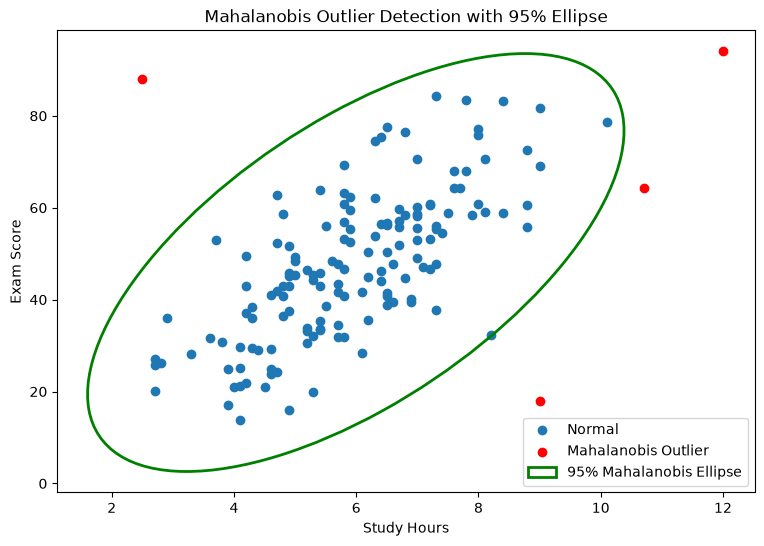

In [42]:
fig, ax = plt.subplots(figsize=(9, 6))

# Normal points
ax.scatter(
    df.loc[~mahal_chi_mask, "study_hours"],
    df.loc[~mahal_chi_mask, "exam_score"],
    label="Normal"
)

# Mahalanobis outliers
ax.scatter(
    df.loc[mahal_chi_mask, "study_hours"],
    df.loc[mahal_chi_mask, "exam_score"],
    color="red",
    label="Mahalanobis Outlier"
)

# Create 95% Mahalanobis ellipse
ellipse = Ellipse(
    xy=mean,
    width=2 * t * np.sqrt(vals[0]),
    height=2 * t * np.sqrt(vals[1]),
    angle=angle,
    fill=False,
    edgecolor="green",
    linewidth=2,
    label="95% Mahalanobis Ellipse"
)

ax.add_patch(ellipse)

ax.set_xlabel("Study Hours")
ax.set_ylabel("Exam Score")
ax.set_title("Mahalanobis Outlier Detection with 95% Ellipse")

ax.legend()

plt.show()

### Scatter Plot Interpretation

The scatter plot shows a positive relationship between study hours and exam score.

The 95% Mahalanobis ellipse represents the main joint distribution of the two variables.

Points outside the ellipse are more unusual because they do not fit the normal relationship between study hours and exam score.

The points highlighted in red are the observations whose Mahalanobis distance exceeds the chi-square-based threshold.

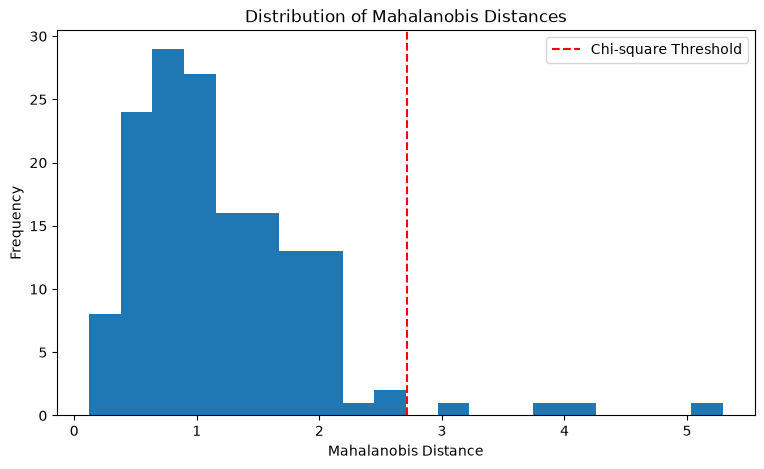

In [43]:
plt.figure(figsize=(9, 5))

plt.hist(
    mahal,
    bins=20
)

plt.axvline(
    mahal_chi_threshold,
    color="red",
    linestyle="--",
    label="Chi-square Threshold"
)

plt.xlabel("Mahalanobis Distance")
plt.ylabel("Frequency")
plt.title("Distribution of Mahalanobis Distances")
plt.legend()

plt.show()

## B10. Euclidean vs Mahalanobis Outliers

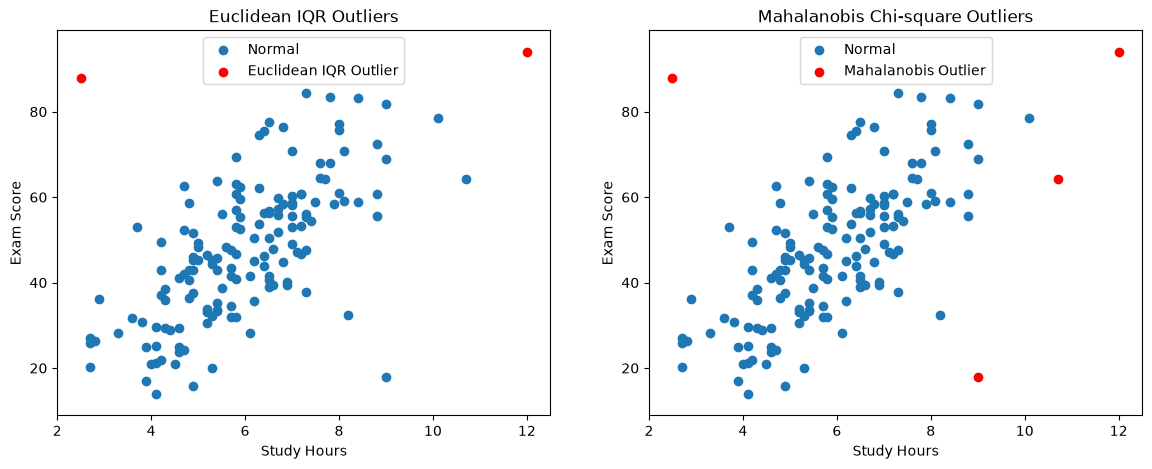

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -------------------------
# Euclidean plot
# -------------------------

axes[0].scatter(
    df.loc[~euclidean_iqr_mask, "study_hours"],
    df.loc[~euclidean_iqr_mask, "exam_score"],
    label="Normal"
)

axes[0].scatter(
    df.loc[euclidean_iqr_mask, "study_hours"],
    df.loc[euclidean_iqr_mask, "exam_score"],
    color="red",
    label="Euclidean IQR Outlier"
)

axes[0].set_xlabel("Study Hours")
axes[0].set_ylabel("Exam Score")
axes[0].set_title("Euclidean IQR Outliers")
axes[0].legend()


# -------------------------
# Mahalanobis plot
# -------------------------

axes[1].scatter(
    df.loc[~mahal_chi_mask, "study_hours"],
    df.loc[~mahal_chi_mask, "exam_score"],
    label="Normal"
)

axes[1].scatter(
    df.loc[mahal_chi_mask, "study_hours"],
    df.loc[mahal_chi_mask, "exam_score"],
    color="red",
    label="Mahalanobis Outlier"
)

axes[1].set_xlabel("Study Hours")
axes[1].set_ylabel("Exam Score")
axes[1].set_title("Mahalanobis Chi-square Outliers")
axes[1].legend()


# Same axis scale
for ax in axes:
    ax.set_xlim(
        df["study_hours"].min() - 0.5,
        df["study_hours"].max() + 0.5
    )

    ax.set_ylim(
        df["exam_score"].min() - 5,
        df["exam_score"].max() + 5
    )

plt.show()

### B10 Interpretation

Euclidean distance measures distance from the centre but does not consider the relationship between study_hours and exam_score.

Mahalanobis distance considers the covariance and correlation between the two variables.

Therefore, Points B and C can receive larger Mahalanobis distances because they break the normal relationship between study hours and exam score.

This allows Mahalanobis distance to detect correlation-based multivariate outliers that Euclidean distance may not detect as strongly.

## B11. Comparing Euclidean and Mahalanobis Outliers

In [45]:
both = euclidean_iqr_mask & mahal_iqr_mask

euclidean_only = euclidean_iqr_mask & ~mahal_iqr_mask

mahalanobis_only = mahal_iqr_mask & ~euclidean_iqr_mask

neither = ~euclidean_iqr_mask & ~mahal_iqr_mask

In [46]:
print("Mahalanobis only:", mahalanobis_only.sum())
print("Euclidean only:", euclidean_only.sum())
print("Both:", both.sum())
print("Neither:", neither.sum())

Mahalanobis only: 2
Euclidean only: 0
Both: 2
Neither: 149


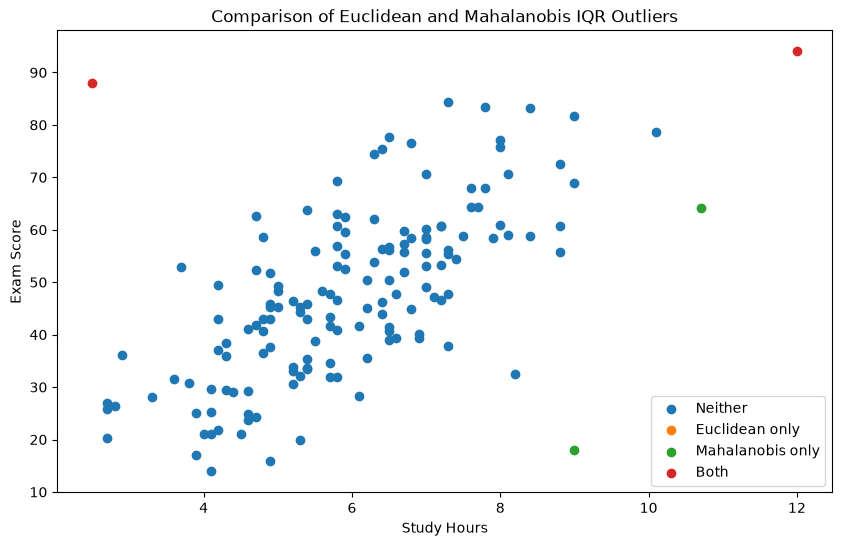

In [47]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df.loc[neither, "study_hours"],
    df.loc[neither, "exam_score"],
    label="Neither"
)

plt.scatter(
    df.loc[euclidean_only, "study_hours"],
    df.loc[euclidean_only, "exam_score"],
    label="Euclidean only"
)

plt.scatter(
    df.loc[mahalanobis_only, "study_hours"],
    df.loc[mahalanobis_only, "exam_score"],
    label="Mahalanobis only"
)

plt.scatter(
    df.loc[both, "study_hours"],
    df.loc[both, "exam_score"],
    label="Both"
)

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Comparison of Euclidean and Mahalanobis IQR Outliers")
plt.legend()

plt.show()

In [48]:
print("Mahalanobis only:")
print(df.index[mahalanobis_only].tolist())

print("\nEuclidean only:")
print(df.index[euclidean_only].tolist())

print("\nBoth:")
print(df.index[both].tolist())

print("\nNeither:")
print(df.index[neither].tolist())

Mahalanobis only:
[87, 152]

Euclidean only:
[]

Both:
[150, 151]

Neither:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149]


### B11 Interpretation

The four categories show how the two outlier detection methods differ.

"Both" contains points flagged by both methods, while "Euclidean only" contains points detected only by Euclidean distance.

"Mahalanobis only" contains points detected only by Mahalanobis distance. These points may be unusual because of the relationship between study_hours and exam_score.

"Neither" contains points that are not flagged by either IQR-based method.

## B12. Three-Variable Mahalanobis Distance

In [49]:
# Create project_score
project_score = np.clip(
    0.7 * df["exam_score"] + rng.normal(0, 8, 153),
    0,
    100
)

df["project_score"] = project_score

print(df.head())

   study_hours  exam_score  project_score
0          7.0        49.1      32.301429
1          5.2        33.9      32.842584
2         10.1        78.6      58.129942
3          7.6        64.4      67.604353
4          3.6        31.6       9.215891


In [51]:
print(df[["study_hours", "exam_score", "project_score"]].head())
print(df.describe().round(2))

   study_hours  exam_score  project_score
0          7.0        49.1      32.301429
1          5.2        33.9      32.842584
2         10.1        78.6      58.129942
3          7.6        64.4      67.604353
4          3.6        31.6       9.215891
       study_hours  exam_score  project_score
count       153.00      153.00         153.00
mean          5.99       48.07          34.00
std           1.62       16.74          15.05
min           2.50       13.90           0.00
25%           4.90       36.00          23.49
50%           5.80       47.20          32.84
75%           7.00       58.80          41.70
max          12.00       94.00          77.95


In [52]:
X3 = df[
    ["study_hours", "exam_score", "project_score"]
].values

print("Shape of X3:", X3.shape)

Shape of X3: (153, 3)


In [53]:
cov3 = np.cov(X3.T)

print("3x3 Covariance Matrix:")
print(cov3)

3x3 Covariance Matrix:
[[  2.61027692  17.06323185  13.81088377]
 [ 17.06323185 280.28733832 217.13122886]
 [ 13.81088377 217.13122886 226.43015128]]


In [54]:
mean3 = X3.mean(axis=0)

print("Mean vector:")
print(mean3)

Mean vector:
[ 5.99281046 48.07385621 33.99921729]


In [55]:
VI3 = np.linalg.inv(cov3)

print("Inverse covariance matrix:")
print(VI3)

Inverse covariance matrix:
[[ 0.63878199 -0.03385234 -0.00649977]
 [-0.03385234  0.0156688  -0.01296053]
 [-0.00649977 -0.01296053  0.0172411 ]]


In [56]:
mahal3 = np.array([
    mahalanobis(x, mean3, VI3)
    for x in X3
])

print("First 5 three-dimensional Mahalanobis distances:")
print(mahal3[:5])

First 5 three-dimensional Mahalanobis distances:
[0.84356979 1.54101452 2.5583163  2.93204136 2.11582106]


In [57]:
mahal3_threshold = np.sqrt(
    chi2.ppf(0.975, df=3)
)

print("3D Mahalanobis threshold:")
print(mahal3_threshold)

3D Mahalanobis threshold:
3.0575159205629903


In [58]:
mahal3_mask = mahal3 > mahal3_threshold

mahal3_indices = df.index[mahal3_mask]

print("Number of 3D outliers:", len(mahal3_indices))
print("3D outlier indices:")
print(mahal3_indices.tolist())

Number of 3D outliers: 4
3D outlier indices:
[87, 150, 151, 152]


In [59]:
newly_flagged = sorted(
    set(mahal3_indices) - set(mahal_chi_indices)
)

print("Newly flagged rows:")
print(newly_flagged)

Newly flagged rows:
[]


In [60]:
print("Details of newly flagged rows:")

if len(newly_flagged) > 0:
    print(df.loc[newly_flagged])
else:
    print("No newly flagged rows.")

Details of newly flagged rows:
No newly flagged rows.


### B12 Interpretation

A third variable, project_score, was added to the dataset.

The covariance matrix changed from 2×2 to 3×3 because there are now three variables.

Mahalanobis distance was recalculated using all three variables, and the chi-square threshold was calculated using 3 degrees of freedom.

The newly flagged rows are: ________.

These rows were not flagged by the original two-variable Mahalanobis method but became outliers when project_score was also considered.

## B13. Mahalanobis Distance from Scratch

In [61]:
X = df[["study_hours", "exam_score"]].values

mean = X.mean(axis=0)

cov = np.cov(X.T)

VI = np.linalg.inv(cov)

In [62]:
mahal_scratch = []

for x in X:
    difference = x - mean
    
    distance = np.sqrt(
        difference.T @ VI @ difference
    )
    
    mahal_scratch.append(distance)

mahal_scratch = np.array(mahal_scratch)

print("First 5 Mahalanobis distances:")
print(mahal_scratch[:5])

First 5 Mahalanobis distances:
[0.75609557 0.84845827 2.55786766 1.09101108 1.48241881]


In [63]:
print("SciPy first 5:")
print(mahal[:5])

print("\nNumPy first 5:")
print(mahal_scratch[:5])

SciPy first 5:
[0.75609557 0.84845827 2.55786766 1.09101108 1.48241881]

NumPy first 5:
[0.75609557 0.84845827 2.55786766 1.09101108 1.48241881]


In [64]:
print(
    "Do both methods match?",
    np.allclose(mahal, mahal_scratch)
)

Do both methods match? True


### B13 Interpretation

Mahalanobis distance was implemented from scratch using NumPy according to the formula:

MD(x) = sqrt((x - μ)^T Σ^-1 (x - μ))

The result was compared with the SciPy implementation using np.allclose().

The result is True, which means the NumPy implementation produces values that match the SciPy implementation within numerical tolerance.